# Análise financeira — ClearBank

Notebook de estudo com dados fictícios. A solução principal usa módulos nativos do Python; pandas e matplotlib aparecem apenas nas etapas opcionais.

## Antes de executar

Use Python 3.10 ou superior. Coloque `transacoes.csv` e `analise_pandas.py` na pasta de trabalho. No Colab, envie os dois arquivos pelo painel **Arquivos**. Execute as células na ordem e salve com as saídas.

O CSV foi criado separadamente, antes da execução: 15 registros válidos em três meses, dez inválidos e uma duplicata. Duas transações excedem R$ 10.000,00. As colunas são `id,data,cliente_id,tipo,valor,descricao,categoria`.

Critérios: datas devem seguir exatamente AAAA-MM-DD; valores devem ser positivos e finitos. Para IDs repetidos, preservamos o primeiro registro válido. Duplicatas são descartadas e incluídas no total de inválidos, com contagem separada. Descrição e categoria podem estar vazias. A média considera os valores de todas as transações, sem sinal. O saldo é crédito menos débito. Valores são arredondados a duas casas na apresentação e exportação.

## 1. Configuração

In [1]:
import csv
import json
import math
import re
from datetime import datetime
from pathlib import Path

LIMITE_SUSPEITO = 10000.00
ARQUIVO_CSV = Path("transacoes.csv")
ARQUIVO_JSON = Path("relatorio.json")
COLUNAS = {"id", "data", "cliente_id", "tipo", "valor", "descricao", "categoria"}
print("Configuração carregada. Limite de suspeita: R$ 10.000,00.")

Configuração carregada. Limite de suspeita: R$ 10.000,00.


## 2. Leitura do CSV
Arquivo ausente ou cabeçalho incompleto impede a análise, com uma mensagem clara. Linhas inválidas são descartadas sem mensagens individuais.

In [2]:
def ler_transacoes(caminho):
    """Retorna registros brutos; None indica falha na leitura."""
    try:
        with open(caminho, encoding="utf-8-sig", newline="") as arquivo:
            leitor = csv.DictReader(arquivo)
            if not COLUNAS.issubset(leitor.fieldnames or []):
                print("CSV inválido: faltam colunas obrigatórias.")
                return None
            return list(leitor)
    except FileNotFoundError:
        print(f"Arquivo não encontrado: {caminho}. Coloque o CSV na pasta de trabalho.")
    except (OSError, UnicodeError, csv.Error) as erro:
        print(f"Não foi possível ler o CSV: {erro}")
    return None

brutas = ler_transacoes(ARQUIVO_CSV)
print(f"Leitura de teste: {len(brutas)} registros." if brutas is not None else "Aguardando CSV.")

Leitura de teste: 26 registros.


## 3. Validação e limpeza

In [3]:
def validar_data(texto):
    if not re.fullmatch(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", texto):
        return None
    try:
        return datetime.strptime(texto, "%Y-%m-%d")
    except ValueError:
        return None


def validar_valor(texto):
    try:
        valor = float(texto)
    except (ValueError, TypeError, OverflowError):
        return None
    return valor if math.isfinite(valor) and valor > 0 else None


def validar_transacao(linha):
    if None in linha:  # Mais campos do que o cabeçalho permite.
        return None
    dados = {campo: (linha.get(campo) or "").strip() for campo in COLUNAS}
    try:
        identificador = int(dados["id"])
    except ValueError:
        return None
    data = validar_data(dados["data"])
    valor = validar_valor(dados["valor"])
    if not dados["cliente_id"] or dados["tipo"] not in ("credito", "debito"):
        return None
    if data is None or valor is None:
        return None
    return {**dados, "id": identificador, "data": data, "valor": valor}


def limpar_transacoes(linhas):
    validas, ids = [], set()
    duplicadas = 0
    for linha in linhas:
        transacao = validar_transacao(linha)
        if transacao is None:
            continue
        if transacao["id"] in ids:
            duplicadas += 1
            continue
        ids.add(transacao["id"])
        validas.append(transacao)
    resumo = {"total": len(linhas), "validas": len(validas),
              "invalidas": len(linhas) - len(validas), "duplicadas": duplicadas}
    return validas, resumo


def exibir_limpeza(resumo):
    print("===== LIMPEZA DOS DADOS =====")
    print(f"Total de linhas lidas: {resumo['total']}")
    print(f"Linhas válidas: {resumo['validas']}")
    print(f"Linhas inválidas: {resumo['invalidas']}")
    print(f"Duplicatas incluídas nas inválidas: {resumo['duplicadas']}")

if brutas is not None:
    validas, limpeza = limpar_transacoes(brutas)
    exibir_limpeza(limpeza)

===== LIMPEZA DOS DADOS =====
Total de linhas lidas: 26
Linhas válidas: 15
Linhas inválidas: 11
Duplicatas incluídas nas inválidas: 1


## 4. Datas, métricas mensais e suspeitas
A soma usa `math.fsum` para reduzir erros de acumulação com floats. A regra de suspeita é estritamente maior que o limite.

In [4]:
def resumir_mes(transacoes):
    valores = [t["valor"] for t in transacoes]
    credito = math.fsum(t["valor"] for t in transacoes if t["tipo"] == "credito")
    debito = math.fsum(t["valor"] for t in transacoes if t["tipo"] == "debito")
    return {"quantidade": len(transacoes), "total_credito": round(credito, 2),
            "total_debito": round(debito, 2), "saldo": round(credito - debito, 2),
            "media": round(math.fsum(valores) / len(valores), 2),
            "maior_valor": round(max(valores), 2), "menor_valor": round(min(valores), 2)}


def obter_periodo(transacoes):
    if not transacoes:
        return {"inicio": None, "fim": None, "dias": 0}
    datas = [t["data"] for t in transacoes]
    inicio, fim = min(datas), max(datas)
    return {"inicio": inicio.strftime("%Y-%m-%d"),
            "fim": fim.strftime("%Y-%m-%d"), "dias": (fim - inicio).days}


def gerar_relatorio(transacoes, limpeza):
    grupos, suspeitas = {}, []
    for t in transacoes:
        mes = t["data"].strftime("%Y-%m")
        grupos.setdefault(mes, []).append(t)
        if t["valor"] > LIMITE_SUSPEITO:
            suspeitas.append({"id": t["id"], "cliente_id": t["cliente_id"],
                              "data": t["data"].strftime("%Y-%m-%d"), "valor": t["valor"]})
    return {"gerado_em": datetime.now().strftime("%Y-%m-%d"),
            "total_transacoes_validas": limpeza["validas"],
            "total_transacoes_invalidas": limpeza["invalidas"],
            "total_duplicadas": limpeza["duplicadas"],
            "periodo": obter_periodo(transacoes),
            "resumo_mensal": {mes: resumir_mes(grupos[mes]) for mes in sorted(grupos)},
            "transacoes_suspeitas": suspeitas}

print("Funções de análise prontas.")

Funções de análise prontas.


## 5. Relatório formatado e exportação

In [5]:
def moeda(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def salvar_json(relatorio, caminho=ARQUIVO_JSON):
    try:
        with open(caminho, "w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
    except (OSError, ValueError, TypeError) as erro:
        print(f"Não foi possível salvar o JSON: {erro}")
        return False
    print(f"Relatório salvo em {caminho}.")
    return True


def exibir_relatorio(relatorio):
    print("\n===== RELATÓRIO MENSAL =====")
    periodo = relatorio["periodo"]
    if periodo["inicio"] is None:
        print("Nenhuma transação válida para análise.")
    else:
        print(f"Período: {periodo['inicio']} → {periodo['fim']} ({periodo['dias']} dias)")
    print(f"Transações válidas: {relatorio['total_transacoes_validas']}")
    print(f"Transações inválidas: {relatorio['total_transacoes_invalidas']}")
    rotulos = {"total_credito": "Total crédito", "total_debito": "Total débito",
               "saldo": "Saldo", "media": "Média", "maior_valor": "Maior valor", "menor_valor": "Menor valor"}
    for mes, dados in relatorio["resumo_mensal"].items():
        print(f"\nMês: {mes}\n  Transações: {dados['quantidade']}")
        for campo, rotulo in rotulos.items():
            print(f"  {rotulo}: {moeda(dados[campo])}")
    print("\n===== TRANSAÇÕES SUSPEITAS =====")
    for t in relatorio["transacoes_suspeitas"]:
        print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data']} | Valor: {moeda(t['valor'])}")
    if not relatorio["transacoes_suspeitas"]:
        print("Nenhuma transação suspeita encontrada.")

print("Exibição e exportação prontas. Exemplo de moeda:", moeda(1234.56))

Exibição e exportação prontas. Exemplo de moeda: R$ 1.234,56


## 6. Testes
Os testes usam pequenos exemplos independentes e arquivos temporários. Nenhum teste modifica o CSV original.

In [6]:
from tempfile import TemporaryDirectory

base = dict(id="1", data="2026-01-01", cliente_id="CLI001", tipo="credito",
            valor="100.00", descricao="Teste", categoria="teste")
assert validar_transacao(base) is not None
for campo, valor in [("id", ""), ("id", "abc"), ("id", "1.5"), ("cliente_id", " "),
                     ("data", "2026-02-30"), ("data", "2026-1-01"), ("tipo", "pix"),
                     ("valor", "abc"), ("valor", "0"), ("valor", "-1"),
                     ("valor", "NaN"), ("valor", "inf")]:
    assert validar_transacao({**base, campo: valor}) is None, (campo, valor)
assert validar_data("2024-02-29") is not None
assert validar_data("2026-02-29") is None
assert validar_transacao({**base, None: ["campo extra"]}) is None
assert validar_transacao({**base, "valor": None}) is None
linhas = [base, base.copy(), {**base, "id": "2", "tipo": "debito", "valor": "40.00", "data": "2026-01-11"}]
vt, lt = limpar_transacoes(linhas)
assert lt == {"total": 3, "validas": 2, "invalidas": 1, "duplicadas": 1}
rt = gerar_relatorio(vt, lt)
assert rt["resumo_mensal"]["2026-01"] == {"quantidade": 2, "total_credito": 100.0,
    "total_debito": 40.0, "saldo": 60.0, "media": 70.0, "maior_valor": 100.0, "menor_valor": 40.0}
assert rt["periodo"]["dias"] == 10
limites = [{**base, "id": str(i), "valor": str(v)} for i, v in enumerate([10000, 10000.01], 1)]
vl, ll = limpar_transacoes(limites)
assert [t["id"] for t in gerar_relatorio(vl, ll)["transacoes_suspeitas"]] == [2]
vz, lz = limpar_transacoes([])
rz = gerar_relatorio(vz, lz)
assert rz["resumo_mensal"] == {} and rz["periodo"]["inicio"] is None
exibir_relatorio(rz)
with TemporaryDirectory() as pasta:
    caminho = Path(pasta)
    assert ler_transacoes(caminho / "ausente.csv") is None
    (caminho / "incompleto.csv").write_text("id,valor\n1,10\n", encoding="utf-8")
    assert ler_transacoes(caminho / "incompleto.csv") is None
    assert salvar_json(rt, caminho / "teste.json")
    assert json.loads((caminho / "teste.json").read_text(encoding="utf-8")) == rt
print("Testes concluídos: validação, datas, duplicatas, cálculos, limite, base vazia, leitura e JSON aprovados.")


===== RELATÓRIO MENSAL =====
Nenhuma transação válida para análise.
Transações válidas: 0
Transações inválidas: 0

===== TRANSAÇÕES SUSPEITAS =====
Nenhuma transação suspeita encontrada.
Arquivo não encontrado: /tmp/tmpyyre0dns/ausente.csv. Coloque o CSV na pasta de trabalho.
CSV inválido: faltam colunas obrigatórias.
Relatório salvo em /tmp/tmpyyre0dns/teste.json.
Testes concluídos: validação, datas, duplicatas, cálculos, limite, base vazia, leitura e JSON aprovados.


## 7. Execução principal

In [7]:
def executar(caminho=ARQUIVO_CSV):
    linhas = ler_transacoes(caminho)
    if linhas is None:
        return None
    transacoes, resumo = limpar_transacoes(linhas)
    exibir_limpeza(resumo)
    resultado = gerar_relatorio(transacoes, resumo)
    exibir_relatorio(resultado)
    salvar_json(resultado)
    return resultado

relatorio = executar()

===== LIMPEZA DOS DADOS =====
Total de linhas lidas: 26
Linhas válidas: 15
Linhas inválidas: 11
Duplicatas incluídas nas inválidas: 1

===== RELATÓRIO MENSAL =====
Período: 2026-01-05 → 2026-03-28 (82 dias)
Transações válidas: 15
Transações inválidas: 11

Mês: 2026-01
  Transações: 5
  Total crédito: R$ 15.500,00
  Total débito: R$ 1.500,40
  Saldo: R$ 13.999,60
  Média: R$ 3.400,08
  Maior valor: R$ 12.000,00
  Menor valor: R$ 69,90

Mês: 2026-02
  Transações: 5
  Total crédito: R$ 5.900,00
  Total débito: R$ 15.419,90
  Saldo: R$ -9.519,90
  Média: R$ 4.263,98
  Maior valor: R$ 15.000,00
  Menor valor: R$ 99,90

Mês: 2026-03
  Transações: 5
  Total crédito: R$ 8.300,00
  Total débito: R$ 1.920,75
  Saldo: R$ 6.379,25
  Média: R$ 2.044,15
  Maior valor: R$ 4.800,00
  Menor valor: R$ 250,00

===== TRANSAÇÕES SUSPEITAS =====
ID: 3 | Cliente: CLI002 | Data: 2026-01-12 | Valor: R$ 12.000,00
ID: 7 | Cliente: CLI002 | Data: 2026-02-10 | Valor: R$ 15.000,00
Relatório salvo em relatorio.json.

## 8. Opcional: comparação com pandas
A leitura e o agrupamento alternativos ficam em um arquivo separado. Reutilizamos as regras de validação para manter o mesmo critério; os cálculos mensais usam `groupby`.

In [8]:
from analise_pandas import analisar_com_pandas, comparar_resultados

if relatorio is not None:
    resumo_pandas = analisar_com_pandas(ARQUIVO_CSV, validar_transacao)
    comparar_resultados(relatorio["resumo_mensal"], resumo_pandas)
    print(json.dumps(resumo_pandas, ensure_ascii=False, indent=2))
else:
    print("Execute a análise principal com um CSV válido primeiro.")

Comparação aprovada: todas as métricas mensais coincidem.
{
  "2026-01": {
    "quantidade": 5,
    "total_credito": 15500.0,
    "total_debito": 1500.4,
    "media": 3400.08,
    "maior_valor": 12000.0,
    "menor_valor": 69.9,
    "saldo": 13999.6
  },
  "2026-02": {
    "quantidade": 5,
    "total_credito": 5900.0,
    "total_debito": 15419.9,
    "media": 4263.98,
    "maior_valor": 15000.0,
    "menor_valor": 99.9,
    "saldo": -9519.9
  },
  "2026-03": {
    "quantidade": 5,
    "total_credito": 8300.0,
    "total_debito": 1920.75,
    "media": 2044.15,
    "maior_valor": 4800.0,
    "menor_valor": 250.0,
    "saldo": 6379.25
  }
}


## 9. Opcional: gráfico do saldo mensal

Gráfico salvo em grafico.png.


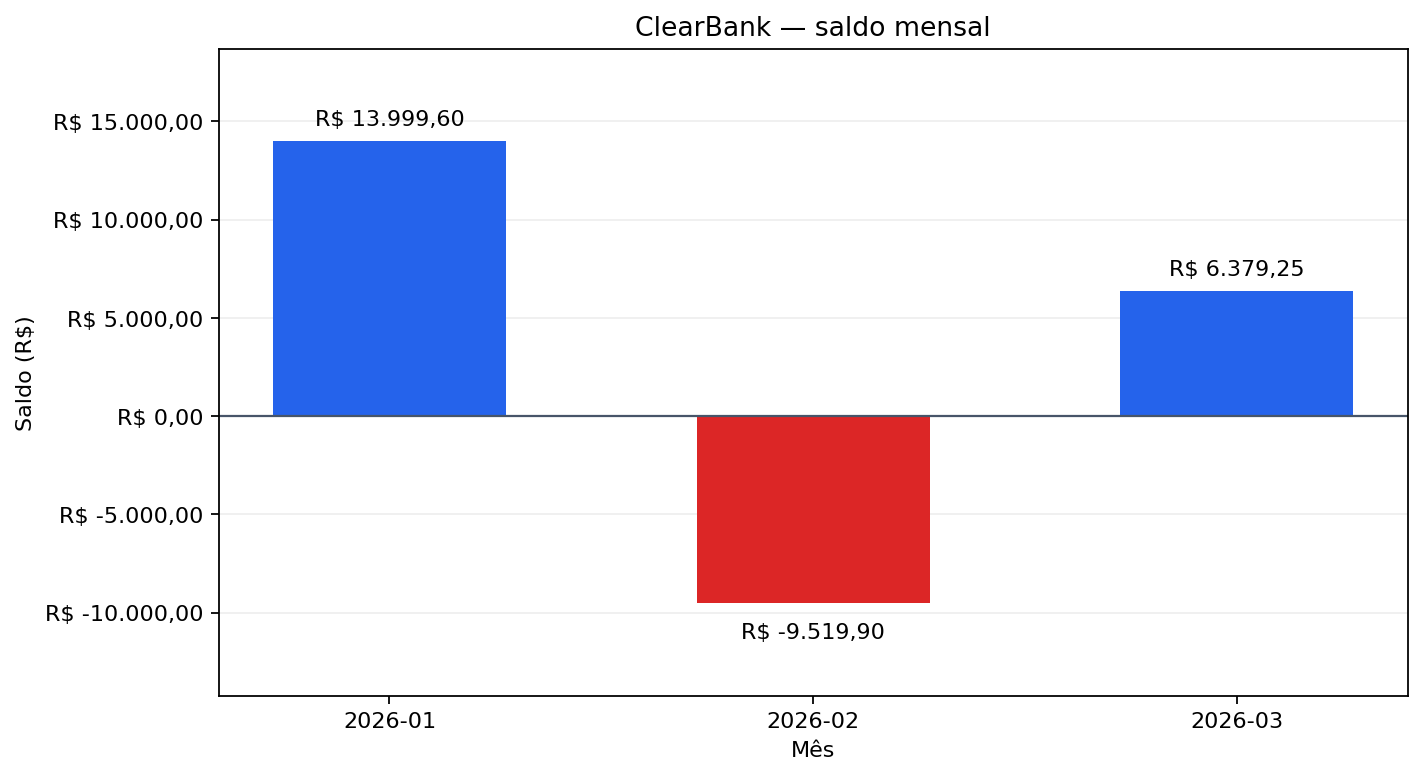

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

if relatorio is not None and relatorio["resumo_mensal"]:
    meses = list(relatorio["resumo_mensal"])
    saldos = [relatorio["resumo_mensal"][mes]["saldo"] for mes in meses]
    fig, ax = plt.subplots(figsize=(9, 5))
    barras = ax.bar(meses, saldos, color=["#2563eb" if v >= 0 else "#dc2626" for v in saldos], width=0.55)
    ax.axhline(0, color="#475569", linewidth=1)
    ax.set(title="ClearBank — saldo mensal", xlabel="Mês", ylabel="Saldo (R$)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, pos: moeda(valor)))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(y=0.20)
    for barra, valor in zip(barras, saldos):
        ax.annotate(moeda(valor), (barra.get_x() + barra.get_width()/2, valor),
                    xytext=(0, 7 if valor >= 0 else -16), textcoords="offset points", ha="center", fontsize=10)
    fig.tight_layout()
    fig.savefig("grafico.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Gráfico salvo em grafico.png.")
else:
    print("Sem dados válidos para gerar o gráfico.")

## Conclusão
O relatório mantém apenas registros válidos e únicos. O sinal de cada saldo depende dos créditos e débitos daquele mês; não representa um saldo bancário acumulado. A sinalização por valor é uma regra do exercício, sem concluir que existe fraude. Para repetir a análise, substitua o CSV e execute todas as células novamente.